In [1]:
import numpy as np
# %pip install matplotlib

# import matplotlib.pyplot as plt


In [2]:
X = np.random.randn(1000,128)
print(X)

[[ 0.39263531 -2.011874    0.04167851 ... -0.34856078 -1.00608264
   0.11149614]
 [-0.14257119 -0.03831623 -0.50688884 ... -1.63471187 -1.6868016
   1.89835407]
 [-1.1067132  -0.36561411  0.39000238 ...  0.4715879  -0.04520455
   0.16023285]
 ...
 [ 0.73213961 -0.72999136  0.31312252 ... -0.13358937  1.33188218
   0.03713504]
 [-1.10769195 -0.43402839 -0.58558833 ...  0.00944549 -0.9625976
  -0.4387473 ]
 [ 0.33112247  0.61784452 -1.11492637 ...  0.70780678 -0.28981915
  -0.08162536]]


In [39]:
layer_dims = [1000] + [500] * 10
print(layer_dims)

[1000, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500]


In [40]:
def initialize_parameters_zeros(layer_dims):
    parameters = {}
    L=len(layer_dims)

    for l in range(1,L):
        parameters['W'+ str(l)] = np.zeros((layer_dims[l],layer_dims[l-1]))
        parameters['b'+ str(l)] = np.zeros((layer_dims[l],1))

    return parameters

In [41]:
def initialize_parameters_small_random(layer_dims):
    parameters = {}
    L = len(layer_dims)

    for l in range(1,L):
        parameters['W'+str(l)] = np.random.randn(layer_dims[l],layer_dims[l-1])*0.01
        parameters['b'+ str(l)] = np.zeros((layer_dims[l],1))

    return parameters

In [43]:
def initialize_parameters_he(layer_dims):
    parameters = {}
    L = len(layer_dims)
    for l in range(1,L):
        parameters['W'+str(l)] = np.random.randn(layer_dims[l],layer_dims[l-1])*np.sqrt(2/(layer_dims[l-1]))
        parameters['b'+ str(l)] = np.zeros((layer_dims[l],1))

    return parameters

In [48]:
# layer_dims = [500] * 11
def forward_pass_and_track_variance(X, parameters):
    variances = []
    L= len(layer_dims)
    A=X
    for l in range(1,L):
        Wl = parameters['W' + str(l)]
        bl = parameters['b' + str(l)]
        Z = np.dot(Wl,A) + bl
        A  =np.maximum(0, Z)
        v = np.var(A)
        variances.append(v)
    print( variances)
    return variances

In [51]:
params_zero = initialize_parameters_zeros(layer_dims)
params_small = initialize_parameters_small_random(layer_dims)
params_he = initialize_parameters_he(layer_dims)

# 2. Run forward pass & track variances
vars_zero = forward_pass_and_track_variance(X, params_zero)
vars_small = forward_pass_and_track_variance(X, params_small)
vars_he = forward_pass_and_track_variance(X, params_he)

[np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0)]
[np.float64(0.034830313356320045), np.float64(0.0008558741573729763), np.float64(2.1566455507114015e-05), np.float64(5.438495989783933e-07), np.float64(1.4646342133081559e-08), np.float64(3.872352804860212e-10), np.float64(9.126090804029982e-12), np.float64(2.1966950343417693e-13), np.float64(5.713586074441131e-15), np.float64(1.4594714123911508e-16)]
[np.float64(0.6879940409821761), np.float64(0.6692399864056828), np.float64(0.7294984828271058), np.float64(0.6640969613625223), np.float64(0.759220896063138), np.float64(0.7627166766492487), np.float64(0.7269435310488802), np.float64(0.6937699225484955), np.float64(0.6676768988315755), np.float64(0.6053618807437368)]


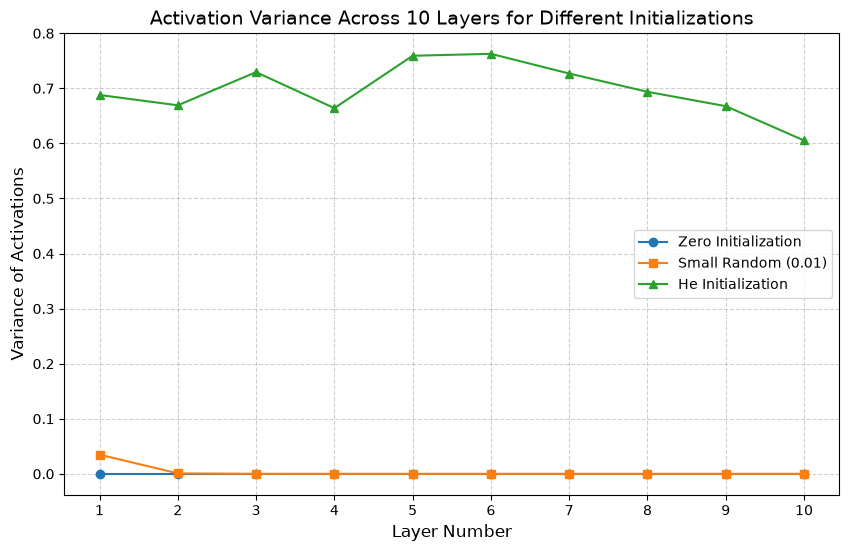

In [52]:
import matplotlib.pyplot as plt

# Define layer indices for the x-axis (1 to 10)
layers = list(range(1, 11))

# Create the plot
plt.figure(figsize=(10, 6))

# Plot each initialization experiment
plt.plot(layers, vars_zero, label='Zero Initialization', marker='o')
plt.plot(layers, vars_small, label='Small Random (0.01)', marker='s')
plt.plot(layers, vars_he, label='He Initialization', marker='^')

# Graph details
plt.title('Activation Variance Across 10 Layers for Different Initializations', fontsize=14)
plt.xlabel('Layer Number', fontsize=12)
plt.ylabel('Variance of Activations', fontsize=12)
plt.xticks(layers)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

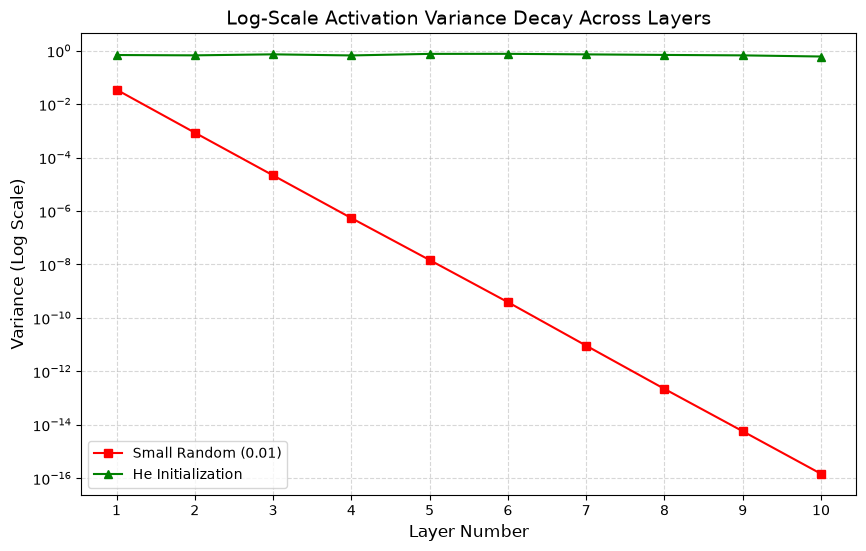

In [53]:
plt.figure(figsize=(10, 6))
plt.plot(layers, vars_small, label='Small Random (0.01)', color='red', marker='s')
plt.plot(layers, vars_he, label='He Initialization', color='green', marker='^')

plt.yscale('log') # Allows you to see exponential collapse cleanly
plt.title('Log-Scale Activation Variance Decay Across Layers', fontsize=14)
plt.xlabel('Layer Number', fontsize=12)
plt.ylabel('Variance (Log Scale)', fontsize=12)
plt.xticks(layers)
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.show()